<a href="https://colab.research.google.com/github/nabillahumi/S5-Mesin_Learning/blob/main/Jobsheet3%20PBL/Praktikum%201%20(JS3)%20PBL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Langkah 1 - Load Data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Memuat dataset cafe
dpath = 'cafes.csv'
df = pd.read_csv(dpath)

# Tampilkan 5 data teratas
df.head()

,cafe_id,name,address,latitude,longitude,rating,review_count,categories,phone,website,scraped_at,source_query
0,ba4b512c-fa2d-4959-8384-8570c81121ec,ARTE COFFEE & EATERY,"Jl. Semeru No.80, Oro-oro Dowo, Kec. Klojen, K...",-7.972556,112.622708,4.7,528,['Kedai Kopi'],0821-3299-9938,instagram.com,2026-10-11T13:54:39.597643,cafe Kota Malang
1,528dfd21-83c6-4946-ab05-391e238caa4a,Nayanika Coffee & Eatery - Malang,"Jl. Brigjend Slamet Riadi No.173, Oro-oro Dowo...",-7.963825,112.627146,4.7,141,['Kafe'],0851-4820-4378,linktr.ee,2026-10-11T13:54:56.561971,cafe Kota Malang
2,cb007499-1d5e-4613-8bbc-c0d30e17b2d2,The Grove Cafe Malang,"Jl. Wilis No.23, Gading Kasri, Kec. Klojen, Ko...",-7.972555,112.618455,4.6,1772,['Kafe'],0888-8299-000,NaN,2026-10-11T13:55:10.909678,cafe Kota Malang
3,f4cd572c-a98d-4309-aa81-6018d889c9d6,Zocco Heritage,"Jl. Raya Lawang - Malang No.34, Klojen, Purwan...",-7.967561,112.633346,4.3,701,['Kedai Kopi'],NaN,instagram.com,2026-10-11T13:55:27.732707,cafe Kota Malang
4,fdd5baff-4477-4188-abf8-4f2a00cf10ee,RASWARA COFFEE AND EATERY,"Jl. Suropati No.1, Klojen, Kec. Klojen, Kota M...",-7.976481,112.634028,4.3,686,['Kafe'],0822-3131-2363,instagram.com,2026-10-11T13:55:43.558923,cafe Kota Malang


#Langkah 2 - Pengecekan Data

In [3]:
# Cek informasi tipe data dan jumlah non-null
df.info()

# Cek jumlah missing value di setiap kolom
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99 entries, 0 to 98
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   cafe_id       99 non-null     object 
 1   name          99 non-null     object 
 2   address       99 non-null     object 
 3   latitude      99 non-null     float64
 4   longitude     99 non-null     float64
 5   rating        99 non-null     float64
 6   review_count  99 non-null     int64  
 7   categories    99 non-null     object 
 8   phone         78 non-null     object 
 9   website       54 non-null     object 
 10  scraped_at    99 non-null     object 
 11  source_query  99 non-null     object 
dtypes: float64(3), int64(1), object(8)
memory usage: 9.4+ KB


,0
cafe_id,0
name,0
address,0
latitude,0
longitude,0
rating,0
review_count,0
categories,0
phone,21
website,45


#Langkah 3 - Imputasi

In [4]:
# Imputasi kolom 'phone' dengan keterangan "Tidak Ada"
df['phone'].fillna(value='Tidak Ada', inplace=True)

# Imputasi kolom 'website' dengan keterangan "Tidak Ada"
df['website'].fillna(value='Tidak Ada', inplace=True)

/tmp/ipykernel_1951/2496591915.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['phone'].fillna(value='Tidak Ada', inplace=True)
/tmp/ipykernel_1951/2496591915.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', t

#Langkah 4 - Validasi Hasil Imputasi

In [5]:
# Validasi kembali jumlah missing value setelah imputasi
print("Jumlah missing value setelah imputasi:")
print(df.isnull().sum())

# Tampilkan verifikasi data langsung
df[['name', 'phone', 'website']].head()

Jumlah missing value setelah imputasi:
cafe_id         0
name            0
address         0
latitude        0
longitude       0
rating          0
review_count    0
categories      0
phone           0
website         0
scraped_at      0
source_query    0
dtype: int64


,name,phone,website
0,ARTE COFFEE & EATERY,0821-3299-9938,instagram.com
1,Nayanika Coffee & Eatery - Malang,0851-4820-4378,linktr.ee
2,The Grove Cafe Malang,0888-8299-000,Tidak Ada
3,Zocco Heritage,Tidak Ada,instagram.com
4,RASWARA COFFEE AND EATERY,0822-3131-2363,instagram.com


#Langkah 5 - Ekstraksi Fitur

In [6]:
# === EKSTRAKSI FITUR ===
# 1. NameLength: Panjang karakter nama kafe
df["NameLength"] = df["name"].str.len()

# 2. RatingBin: Pengelompokan rating kafe
df["RatingBin"] = pd.cut(df["rating"], bins=[0, 4.0, 4.5, 5.0], labels=["Standard", "Good", "Excellent"])

# 3. HasPhone: Status kepemilikan nomor telepon (1 ada, 0 tidak ada)
df["HasPhone"] = df["phone"].apply(lambda x: 0 if x == 'Tidak Ada' else 1)

# 4. ReviewCountBin: Pengelompokan jumlah ulasan
df["ReviewCountBin"] = pd.qcut(df["review_count"], q=3, labels=["Low", "Medium", "High"])

# 5. DomainWebsite: Ekstraksi domain website
df["DomainWebsite"] = df["website"].apply(lambda x: str(x).split('/')[0] if x != 'Tidak Ada' else 'None')

print("✅ Hasil Ekstraksi Fitur Selesai!")
df[["name", "NameLength", "RatingBin", "HasPhone", "ReviewCountBin", "DomainWebsite"]].head()

✅ Hasil Ekstraksi Fitur Selesai!


,name,NameLength,RatingBin,HasPhone,ReviewCountBin,DomainWebsite
0,ARTE COFFEE & EATERY,20,Excellent,1,Medium,instagram.com
1,Nayanika Coffee & Eatery - Malang,33,Excellent,1,Low,linktr.ee
2,The Grove Cafe Malang,21,Excellent,1,High,None
3,Zocco Heritage,14,Good,0,Medium,instagram.com
4,RASWARA COFFEE AND EATERY,25,Good,1,Medium,instagram.com


#Langkah 6 - Visualisasi Hasil Ektraksi Fitur

/tmp/ipykernel_1951/1751669783.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="RatingBin", data=df, palette="viridis", order=["Standard", "Good", "Excellent"])


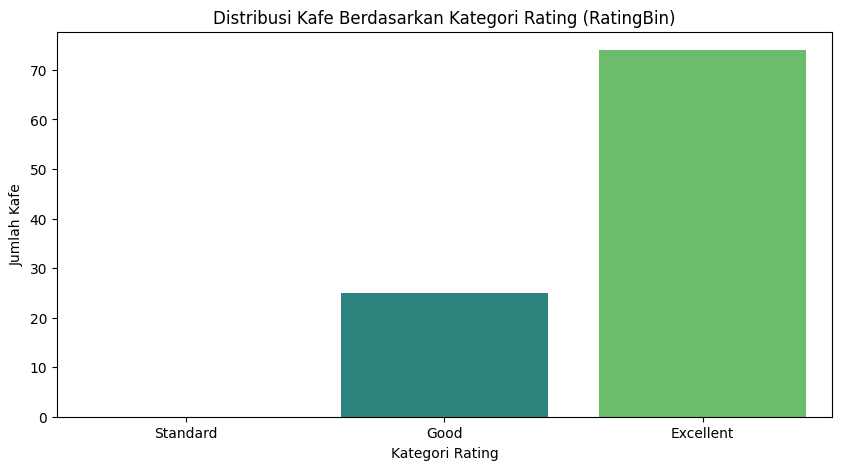

/tmp/ipykernel_1951/1751669783.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="HasPhone", data=df, palette="Set2")


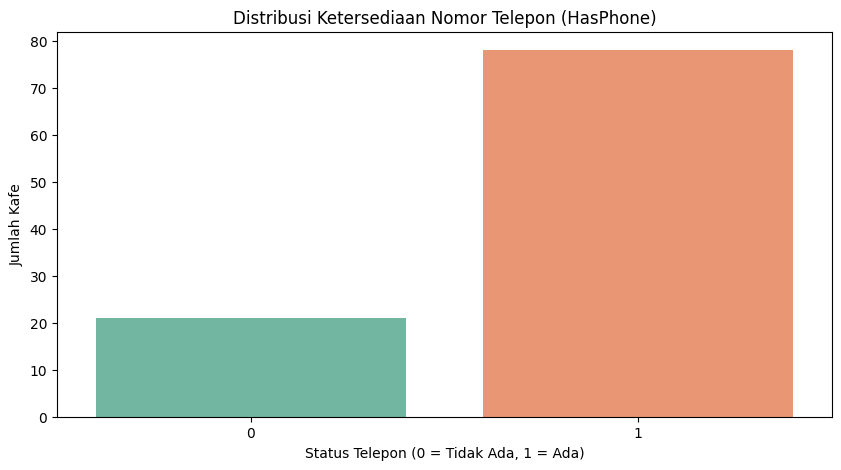

/tmp/ipykernel_1951/1751669783.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="ReviewCountBin", data=df, palette="magma", order=["Low", "Medium", "High"])


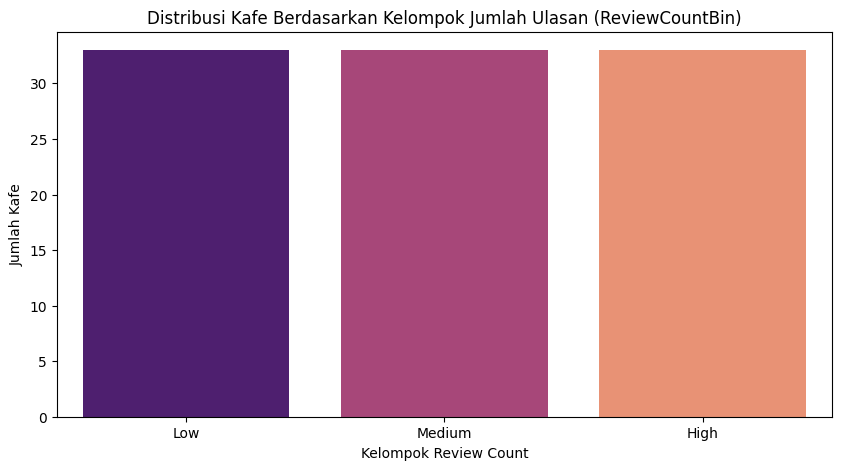

In [7]:
# === VISUALISASI FITUR HASIL EKSTRAKSI ===
plt.figure(figsize=(10, 5))
sns.countplot(x="RatingBin", data=df, palette="viridis", order=["Standard", "Good", "Excellent"])
plt.title("Distribusi Kafe Berdasarkan Kategori Rating (RatingBin)")
plt.xlabel("Kategori Rating")
plt.ylabel("Jumlah Kafe")
plt.show()

plt.figure(figsize=(10, 5))
sns.countplot(x="HasPhone", data=df, palette="Set2")
plt.title("Distribusi Ketersediaan Nomor Telepon (HasPhone)")
plt.xlabel("Status Telepon (0 = Tidak Ada, 1 = Ada)")
plt.ylabel("Jumlah Kafe")
plt.show()

plt.figure(figsize=(10, 5))
sns.countplot(x="ReviewCountBin", data=df, palette="magma", order=["Low", "Medium", "High"])
plt.title("Distribusi Kafe Berdasarkan Kelompok Jumlah Ulasan (ReviewCountBin)")
plt.xlabel("Kelompok Review Count")
plt.ylabel("Jumlah Kafe")
plt.show()